Epoch 1/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - loss: 0.9625 - val_loss: 0.8898
Epoch 2/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.8465 - val_loss: 0.7679
Epoch 3/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.7065 - val_loss: 0.6434
Epoch 4/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.5609 - val_loss: 0.5788
Epoch 5/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4812 - val_loss: 0.5675
Epoch 6/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4582 - val_loss: 0.5434
Epoch 7/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4427 - val_loss: 0.4941
Epoch 8/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4162 - val_loss: 0.4667
Epoch 9/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.4038 - val_loss: 0.4536
Epoch 10/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3948 - val_loss: 0.4513
Epoch 11/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3866 - val_loss: 0.4484
Epoch 12/100
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.3836 - val_loss: 0.4498


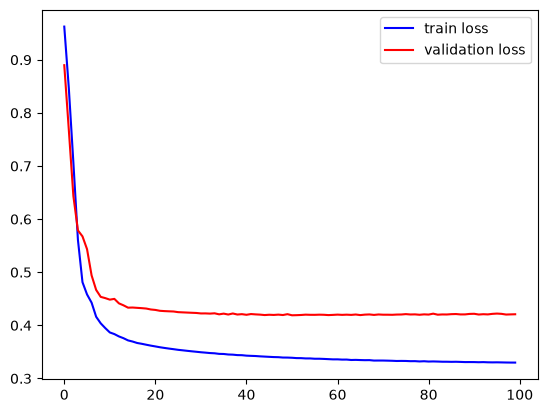

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step

Accuracy of the test data = 0.840000


In [1]:
# [MXDL-5-01] 3.wb_custom_regularizer.py
import numpy as np
import tensorflow as tf
from sklearn.model_selection import train_test_split
from tensorflow.keras.layers import Input, Dense
from tensorflow.keras.models import Model
from tensorflow.keras import optimizers
from tensorflow.keras import regularizers
import matplotlib.pyplot as plt
import pickle

# Read a saved dataset
with open('data/blobs.pkl', 'rb') as f:
    x_train, x_test, y_train, y_test = pickle.load(f)

# Create an ANN model.
n_input = x_train.shape[1]   # number of input neurons
n_output = 1                 # number of output neurons
n_hidden = 32                # number of hidden neurons
R = 0.01                     # regularization constant
adam = optimizers.Adam(learning_rate=0.005)

# Custom regularizer for L3 regularization
# L3 regularization is rarely used, but if you want to use
# it for some reason, you can implement it using a custom
# regularizer like this.
class reg_L3(regularizers.Regularizer):
    def __init__(self, reg_lambda):
        self.R = reg_lambda

    def __call__(self, x):
        # The w or b of a layer is passed to x.
        return self.R * tf.reduce_sum(tf.math.pow(tf.math.abs(x),3))

# The data is simple, but we intentionally added many hidden
# layers to the model to demonstrate the effect of regularization.
x_input = Input(batch_shape=(None, n_input))
h = Dense(n_hidden, activation = 'relu',
          kernel_regularizer=reg_L3(R),
          bias_regularizer=reg_L3(R))(x_input)

# 4 more hidden layers
for i in range(4):
    h = Dense(n_hidden, activation = 'relu',
              kernel_regularizer=reg_L3(R),
              bias_regularizer=reg_L3(R))(h)

y_output = Dense(n_output, activation='sigmoid',
                 kernel_regularizer=reg_L3(R),
                 bias_regularizer=reg_L3(R))(h)

model = Model(x_input, y_output)
model.compile(loss='binary_crossentropy',
              optimizer = adam)
h = model.fit(x_train, y_train, epochs=100, batch_size=50,
              validation_data=[x_test, y_test])

# Visually see the loss history
plt.plot(h.history['loss'], c='blue', label='train loss')
plt.plot(h.history['val_loss'], c='red', label='validation loss')
plt.legend()
plt.show()

# Check the accuracy of the test data
# Check the accuracy of the test data
y_pred = (model.predict(x_test) > 0.5) * 1
acc = (y_pred == y_test).mean()
print("\nAccuracy of the test data = {:4f}".format(acc))